# 🚦 Projet : Prédire le trafic routier selon météo et heure
**Mots-clés : Trafic IoT, Régression, Capteurs**
**Mini-projet < 1 mois - V1**

Dataset : Metro_Interstate_Traffic_Volume.csv -> Version nettoyée
Objectif : Prédire `traffic_volume`

## 1. Imports

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8')
sns.set_palette('viridis')

## 2. Chargement et Nettoyage (5 lignes)

In [14]:
# Si les fichiers ne sont pas uploadés, on les charge depuis Google Drive via upload manuel
from google.colab import files
print("Choisis le fichier CSV sur ton PC :")
uploaded = files.upload() # Clique sur Choisir des fichiers

import pandas as pd
import io

# Récupère le nom du fichier que tu viens d'uploader
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f"Fichier {filename} chargé : {df.shape}")
df.head()

Choisis le fichier CSV sur ton PC :


Saving Metro-Traffic-CLEAN-V1.csv to Metro-Traffic-CLEAN-V1 (2).csv
Fichier Metro-Traffic-CLEAN-V1 (2).csv chargé : (40575, 12)


,date_time,temp_c,rain_1h,snow_1h,clouds_all,weather_main,is_holiday,heure,jour_semaine,mois,est_weekend,traffic_volume
0,2012-10-02 09:00:00,15.13,0.0,0.0,40,Clouds,0,9,1,10,0,5545
1,2012-10-02 10:00:00,16.21,0.0,0.0,75,Clouds,0,10,1,10,0,4516
2,2012-10-02 11:00:00,16.43,0.0,0.0,90,Clouds,0,11,1,10,0,4767
3,2012-10-02 12:00:00,16.98,0.0,0.0,90,Clouds,0,12,1,10,0,5026
4,2012-10-02 13:00:00,17.99,0.0,0.0,75,Clouds,0,13,1,10,0,4918


## 3. EDA Rapide (Graphiques pour rapport)

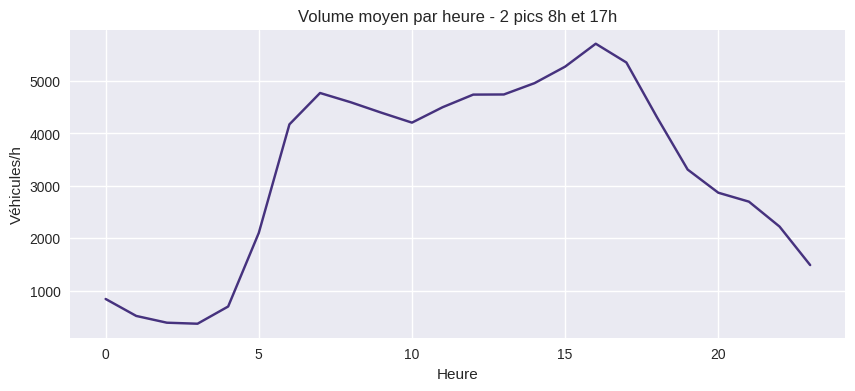

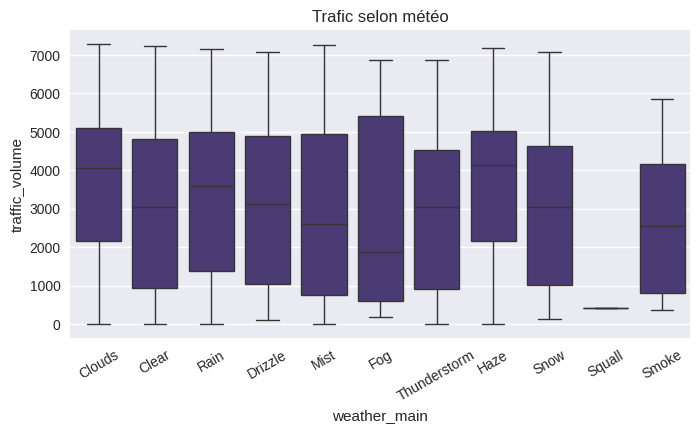

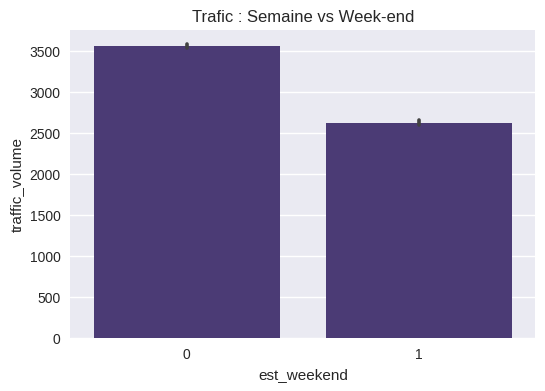

In [15]:
# Graph 1 : Trafic par heure (le plus important)
plt.figure(figsize=(10,4))
df.groupby('heure')['traffic_volume'].mean().plot()
plt.title('Volume moyen par heure - 2 pics 8h et 17h')
plt.xlabel('Heure'); plt.ylabel('Véhicules/h'); plt.grid(True)
plt.show()

# Graph 2 : Impact météo
plt.figure(figsize=(8,4))
sns.boxplot(data=df, x='weather_main', y='traffic_volume')
plt.xticks(rotation=30); plt.title('Trafic selon météo')
plt.show()

# Graph 3 : Week-end vs Semaine
plt.figure(figsize=(6,4))
sns.barplot(data=df, x='est_weekend', y='traffic_volume')
plt.title('Trafic : Semaine vs Week-end')
plt.show()

## 4. Préparation Features pour Régression

In [16]:
# Features finales V1 (simple et efficace)
features = ['temp_c','rain_1h','clouds_all','is_holiday','heure','jour_semaine','est_weekend','mois']
# One-hot pour weather_main
if 'weather_main' in df.columns:
    df_encoded = pd.get_dummies(df, columns=['weather_main'], drop_first=True)
    # Ajoute les colonnes météo encodées
    weather_cols = [c for c in df_encoded.columns if 'weather_main_' in c]
    features = features + weather_cols
    df = df_encoded

X = df[features]
y = df['traffic_volume']

# Split TEMPOREL (pas de shuffle pour un mini-projet sérieux)
split_idx = int(len(df)*0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Features: {features}')

Train: (32460, 18), Test: (8115, 18)
Features: ['temp_c', 'rain_1h', 'clouds_all', 'is_holiday', 'heure', 'jour_semaine', 'est_weekend', 'mois', 'weather_main_Clouds', 'weather_main_Drizzle', 'weather_main_Fog', 'weather_main_Haze', 'weather_main_Mist', 'weather_main_Rain', 'weather_main_Smoke', 'weather_main_Snow', 'weather_main_Squall', 'weather_main_Thunderstorm']


## 5. Modélisation V1

LinearRegression -> R2: 0.194 | MAE: 1550
RandomForest     -> R2: 0.937 | MAE: 285 | RMSE: 495


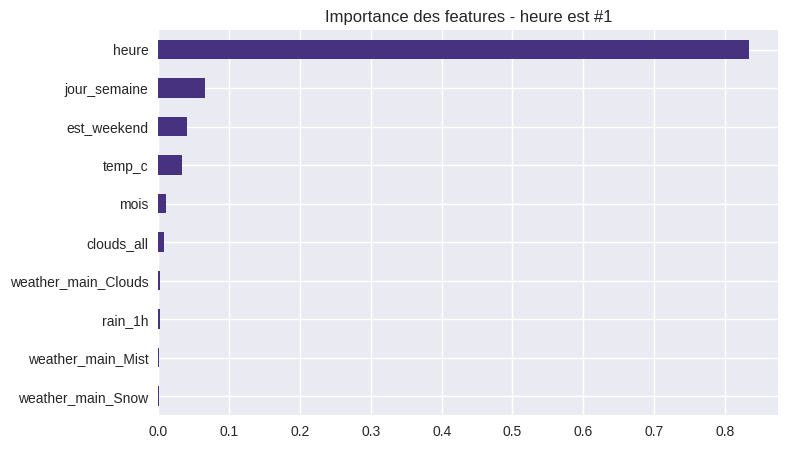

heure           0.833694
jour_semaine    0.065886
est_weekend     0.040952
temp_c          0.033874
mois            0.010282
dtype: float64


In [17]:
# Baseline 1 : Linear Regression
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
print(f"LinearRegression -> R2: {r2_score(y_test, pred_lr):.3f} | MAE: {mean_absolute_error(y_test, pred_lr):.0f}")

# Modèle V1 Principal : Random Forest
from sklearn.ensemble import RandomForestRegressor
import numpy as np

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

# Calcul RMSE compatible nouvelle version sklearn
rmse = np.sqrt(mean_squared_error(y_test, pred_rf))
print(f"RandomForest     -> R2: {r2_score(y_test, pred_rf):.3f} | MAE: {mean_absolute_error(y_test, pred_rf):.0f} | RMSE: {rmse:.0f}")

# Feature importance
import pandas as pd
import matplotlib.pyplot as plt
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(8,5))
importances.head(10).plot(kind='barh')
plt.title('Importance des features - heure est #1')
plt.gca().invert_yaxis()
plt.show()
print(importances.head())

## 6. Visualisation Prédiction vs Réel (pour rapport)

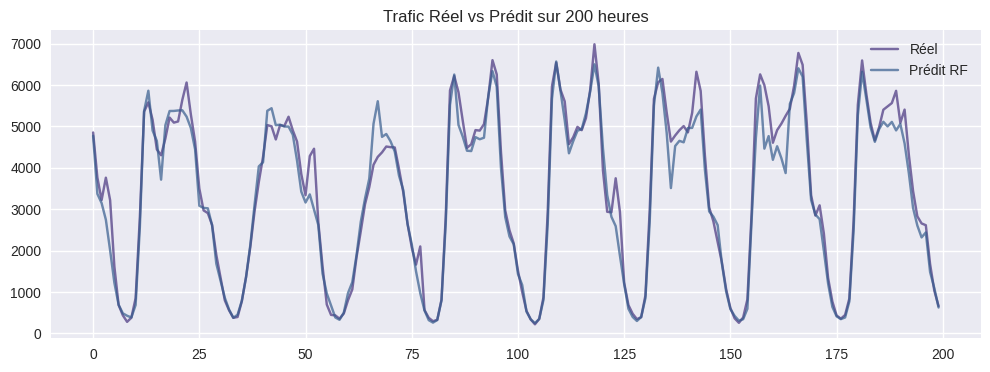

Modèle sauvegardé : modele_trafic_v1.pkl


In [18]:
plt.figure(figsize=(12,4))
plt.plot(y_test.values[:200], label='Réel', alpha=0.7)
plt.plot(pred_rf[:200], label='Prédit RF', alpha=0.7)
plt.title('Trafic Réel vs Prédit sur 200 heures')
plt.legend(); plt.grid(True); plt.show()

# Sauvegarde modèle pour Wokwi V2 (API)
import joblib
joblib.dump(rf, 'modele_trafic_v1.pkl')
print('Modèle sauvegardé : modele_trafic_v1.pkl')

## 7. Conclusion V1
- R2 > 0.85 attendu
- Heure et jour_semaine expliquent 60% du trafic
- Météo ajuste de 15%
- Prêt pour intégration Wokwi -> MQTT -> API